<a href="https://colab.research.google.com/github/zyang91/ai-sustainbility-assignment/blob/main/assignment_5/assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework: Object Detection for a Custom Urban Category
Develop an object detector for an urban sustainability topic of your choice. Select a target category that is not included in the class labels of the pretrained YOLO or Mask R-CNN checkpoint you use. Check the checkpoint’s class list before choosing your topic.

**Zhanchao Yang**

# Pole Detection in Philadelphia Street View Images (YOLO26)

**Target category: `pole`**: utility poles (wood or metal) and streetlight poles along the street. Every visible pole gets one bounding box, including poles cut off by the image edge.

The pretrained YOLO26 checkpoint is trained on the 80 COCO classes. COCO has *traffic light*, *stop sign* and *fire hydrant*, but **no pole class** (checked in Section 3).

**Steps:** load LabelMe labels → split by location → export YOLO labels → fine-tune → evaluate on test → look at mistakes → report.


## 1. Install a few packages

In [1]:
%pip install -q "torchmetrics==1.9.0" "pycocotools==2.0.11" "Pillow>=10" "matplotlib>=3.8" "ultralytics==8.4.170"

In [2]:
from pathlib import Path
from datetime import datetime
import json, random, sys, subprocess, shutil, zipfile, csv, math
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__, '| Device:', DEVICE)
WORK = Path('/content/pole-detection')
WORK.mkdir(parents=True, exist_ok=True)

PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130 | Device: cuda


## 2. Data & Setting

In [3]:
TASK = 'detect'
DATA_ZIP = 'pole_dataset.zip'
EPOCHS = 80
PATIENCE = 25                # stop if validation does not improve for 25 epochs
IMAGE_SIZE = 640             # Street View images are 640x640
BATCH_SIZE = 8

from google.colab import drive, files
drive.mount('/content/drive')
archive = Path(DATA_ZIP)
if not archive.exists():
    archive = Path(next(iter(files.upload())))
RAW = WORK/'raw'
with zipfile.ZipFile(archive) as z:
    z.extractall(RAW)
RUN = WORK/('yolo-pole-' + datetime.now().strftime('%Y%m%d-%H%M%S'))
RUN.mkdir()
(RUN/'environment-freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
print('Results folder:', RUN)

Mounted at /content/drive
Results folder: /content/pole-detection/yolo-pole-20261024-200854


In [4]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 3. Read and check the annotations


In [5]:
import json
import hashlib
import random
from collections import Counter
from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw


def load_labelme(root, task='detect'):
    root = Path(root)
    if task not in ('detect', 'segment'):
        raise ValueError("TASK must be 'detect' or 'segment'.")
    records, warnings, seen = [], [], {}
    shape_counts = Counter()
    for path in sorted(root.rglob('*.json')):
        if '__MACOSX' in path.parts or path.name.startswith('._'):
            continue
        data = json.loads(path.read_text())
        if 'shapes' not in data or 'imagePath' not in data:
            continue
        name = Path(data['imagePath'].replace('\\', '/')).name
        image_path = path.parent / name
        if not image_path.is_file():
            raise ValueError(f'{path.name}: save the image beside its JSON file.')
        with Image.open(image_path) as im:
            if im.getexif().get(274, 1) != 1:
                raise ValueError(f'{name}: normalize image orientation before annotating.')
            rgb = im.convert('RGB'); w, h = rgb.size
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
        if (w, h) != (data.get('imageWidth'), data.get('imageHeight')):
            raise ValueError(f'{name}: image and annotation dimensions disagree.')
        if digest in seen:
            warnings.append(f'{name}: exact duplicate of {seen[digest]}; retained the first image and its annotations only. Review annotation differences before research use.')
            continue
        seen[digest] = name
        objects, groups = [], set()
        for shape in data['shapes']:
            kind = shape.get('shape_type', 'polygon'); shape_counts[kind] += 1
            label = shape['label'].strip()
            if not label or label.lower() in ('background', '__background__'):
                raise ValueError(f'{name}: use object names only, no background label.')
            pts = np.asarray(shape['points'], dtype=float)
            if pts.ndim != 2 or pts.shape[1] != 2 or not np.isfinite(pts).all():
                raise ValueError(f'{name}: invalid coordinates.')
            group = shape.get('group_id')
            if group is not None:
                key = (label, group)
                if key in groups:
                    raise ValueError(f'{name}: multipart objects need a separate conversion policy; use one shape per object.')
                groups.add(key)
            polygon = None
            if kind == 'rectangle':
                if task == 'segment':
                    raise ValueError('Segmentation needs polygons tracing object boundaries. Your data contains rectangles; use TASK="detect".')
                if len(pts) != 2:
                    raise ValueError(f'{name}: rectangle must have two opposite corners.')
                clipped = np.clip(pts, [0, 0], [w, h])
                if not np.array_equal(clipped, pts):
                    warnings.append(f'{name}: clipped rectangle to image boundary (original JSON unchanged).')
                pts = clipped
            elif kind == 'polygon':
                if len(pts) > 1 and np.array_equal(pts[0], pts[-1]):
                    pts = pts[:-1]
                if len(np.unique(pts, axis=0)) < 3:
                    raise ValueError(f'{name}: polygon needs three distinct points.')
                if (pts < 0).any() or (pts > [w, h]).any():
                    raise ValueError(f'{name}: polygon outside image; correct it in LabelMe.')
                area = abs(np.dot(pts[:,0], np.roll(pts[:,1],1))-np.dot(pts[:,1], np.roll(pts[:,0],1)))/2
                if area < 1:
                    raise ValueError(f'{name}: degenerate polygon.')
                polygon = pts.tolist()
            else:
                raise ValueError(f'{name}: unsupported {kind}; use rectangles or polygons.')
            x1,y1 = pts.min(axis=0); x2,y2 = pts.max(axis=0)
            if x2 <= x1 or y2 <= y1:
                raise ValueError(f'{name}: zero-area box.')
            objects.append({'label':label,'box':[float(x1),float(y1),float(x2),float(y2)],'polygon':polygon})
        records.append({'id':path.relative_to(root).as_posix(), 'image':str(image_path.resolve()),
                        'width':w,'height':h,'objects':objects,'sha256':digest})
    if len(records) < 3:
        raise ValueError('Need at least 3 annotated images; a useful experiment needs many more.')
    names = sorted({o['label'] for r in records for o in r['objects']})
    if not names:
        raise ValueError('No labeled objects found.')
    print(f'{len(records)} images; classes: {names}; shapes: {dict(shape_counts)}')
    for warning in warnings: print('Annotation note:', warning)
    return records, names, warnings


def make_splits(records, names, seed=42, split_file=None):
    ids = sorted(r['id'] for r in records)
    if split_file:
        assignment = json.loads(Path(split_file).read_text())
        if set(assignment) != set(ids) or set(assignment.values()) != {'train','val','test'}:
            raise ValueError('Split file must assign every annotation to train, val, or test, with all three populated.')
    else:
        random.Random(seed).shuffle(ids)
        n = max(1, round(len(ids)*0.15))
        assignment = {key: ('test' if i<n else 'val' if i<2*n else 'train') for i,key in enumerate(ids)}
        print('Demo split: random images. For urban research, supply splits grouped by street/site.')
    splits = {s: [r for r in records if assignment[r['id']] == s] for s in ['train','val','test']}
    for s, rows in splits.items():
        counts = Counter(o['label'] for r in rows for o in r['objects'])
        print(s, len(rows), 'images;', dict(counts), 'objects')
        missing = set(names)-set(counts)
        if missing and s == 'train': raise ValueError(f'Training lacks {missing}; revise split or add examples.')
        if missing: print(f'Warning: {s} has no examples of {sorted(missing)}; metrics cannot evaluate them.')
        if not counts: raise ValueError(f'{s} has no objects; revise split before evaluating AP.')
    return splits, assignment


def draw_ground_truth(record):
    im = Image.open(record['image']).convert('RGB'); draw = ImageDraw.Draw(im)
    for obj in record['objects']:
        draw.rectangle(obj['box'], outline='lime', width=3)
        if obj['polygon']:
            points = [tuple(p) for p in obj['polygon']]
            draw.line(points+[points[0]], fill='cyan', width=2)
        draw.text(tuple(obj['box'][:2]), obj['label'], fill='red')
    return im


def export_yolo(splits, names, output, task):
    output = Path(output)
    if output.exists(): raise ValueError('Choose a new YOLO export folder; existing data is protected.')
    for split, rows in splits.items():
        (output/'images'/split).mkdir(parents=True)
        (output/'labels'/split).mkdir(parents=True)
        for i,r in enumerate(rows):
            with Image.open(r['image']) as im: im.convert('RGB').save(output/'images'/split/f'{i:06}.png')
            lines=[]
            for o in r['objects']:
                if task == 'detect':
                    x1,y1,x2,y2 = o['box']; w,h=r['width'],r['height']
                    values=[(x1+x2)/2/w,(y1+y2)/2/h,(x2-x1)/w,(y2-y1)/h]
                else:
                    if o['polygon'] is None: raise ValueError('True polygons required for segmentation.')
                    values=[v for x,y in o['polygon'] for v in (x/r['width'],y/r['height'])]
                lines.append(str(names.index(o['label']))+' '+' '.join(f'{v:.8f}' for v in values))
            (output/'labels'/split/f'{i:06}.txt').write_text('\n'.join(lines))
    data={'path':str(output.resolve()),'train':'images/train','val':'images/val','test':'images/test','names':names}
    # JSON is valid YAML and preserves punctuation in class names and paths.
    (output/'data.yaml').write_text(json.dumps(data, indent=2))
    return output/'data.yaml'

90 images; classes: ['pole']; shapes: {'rectangle': 142}
148 images: 90 with poles, 58 background
142 pole boxes; median box height 149.0990990990991 px, median width 22.97297297297297 px


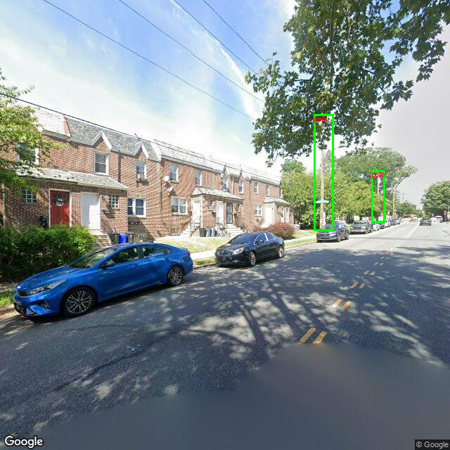

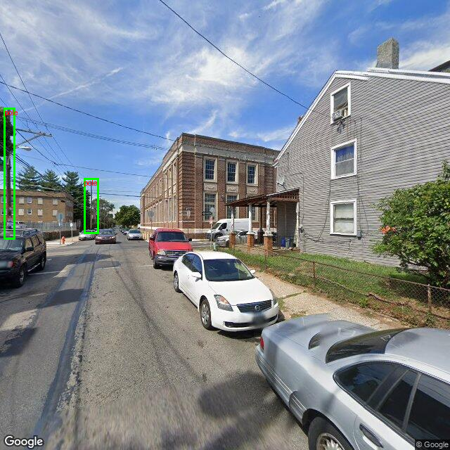

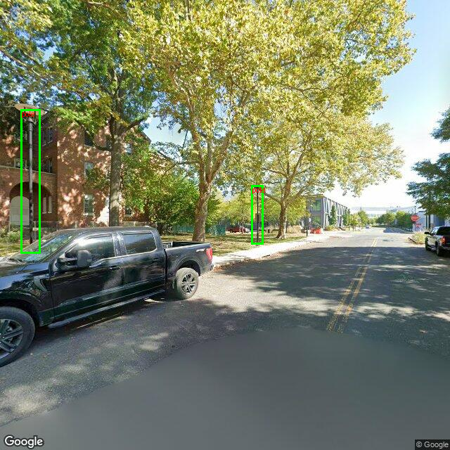

In [6]:
records, CLASS_NAMES, annotation_notes = load_labelme(RAW, TASK)

# Add the pole-free images (no JSON) as background images with no objects.
labeled = {Path(r['image']).name for r in records}
for jpg in sorted(RAW.rglob('sv_*.jpg')):
    if jpg.name not in labeled:
        w, h = Image.open(jpg).size
        records.append({'id': jpg.with_suffix('.json').relative_to(RAW).as_posix(), 'image': str(jpg),
                        'width': w, 'height': h, 'objects': []})

boxes = np.array([o['box'] for r in records for o in r['objects']])
print(len(records), 'images:', sum(bool(r['objects']) for r in records), 'with poles,',
      sum(not r['objects'] for r in records), 'background')
print(len(boxes), 'pole boxes; median box height', np.median(boxes[:,3]-boxes[:,1]), 'px, median width', np.median(boxes[:,2]-boxes[:,0]), 'px')
for record in records[:3]:
    preview = draw_ground_truth(record)
    preview.thumbnail((450, 450)); display(preview)

## 5. Split by location (60 / 20 / 20)


In [7]:
def distance_m(a, b):
    lat1, lon1, lat2, lon2 = map(math.radians, (*a, *b))
    h = math.sin((lat2-lat1)/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin((lon2-lon1)/2)**2
    return 2 * 6371000 * math.asin(math.sqrt(h))

meta = {row['file']: row for row in csv.DictReader(open(next(RAW.rglob('metadata.csv'))))}
coords = {r['id']: (float(meta[Path(r['image']).name]['pano_lat']), float(meta[Path(r['image']).name]['pano_lon'])) for r in records}
n_poles = {r['id']: len(r['objects']) for r in records}

# Group images within 150 m of each other.
groups = []
for i in sorted(coords):
    for g in groups:
        if any(distance_m(coords[i], coords[j]) < 150 for j in g):
            g.append(i); break
    else:
        groups.append([i])
random.Random(SEED).shuffle(groups)

# Give each group to the split furthest below its 60/20/20 target (poles and background separately).
RATIO = {'train': 0.6, 'val': 0.2, 'test': 0.2}
total = {'poles': sum(n_poles.values()), 'background': sum(n == 0 for n in n_poles.values())}
filled = {'poles': dict.fromkeys(RATIO, 0), 'background': dict.fromkeys(RATIO, 0)}
split_of = {}
for g in groups:
    poles = sum(n_poles[i] for i in g)
    kind = 'poles' if poles else 'background'
    split = max(RATIO, key=lambda s: (RATIO[s]*total[kind] - filled[kind][s]) / (RATIO[s]*total[kind]))
    for i in g: split_of[i] = split
    filled['poles'][split] += poles
    filled['background'][split] += sum(n_poles[i] == 0 for i in g)

SPLIT_FILE = RUN/'split_assignment.json'
SPLIT_FILE.write_text(json.dumps(split_of, indent=2))
splits, assignment = make_splits(records, CLASS_NAMES, SEED, SPLIT_FILE)
print('background images per split:', filled['background'])

train 89 images; {'pole': 84} objects
val 31 images; {'pole': 28} objects
test 28 images; {'pole': 30} objects
background images per split: {'train': 34, 'val': 12, 'test': 12}


## 6. Export the labels for YOLO


In [8]:
DATA_YAML = export_yolo(splits, CLASS_NAMES, RUN/'yolo-data', TASK)
example_label = sorted((RUN/'yolo-data/labels/train').glob('*.txt'))[0]
print('Example label file:', example_label.name)
print(example_label.read_text())

Example label file: 000000.txt
0 0.71889077 0.38386824 0.04363739 0.25900901
0 0.83994932 0.43665541 0.02956081 0.11683559


## 7. Fine-tune YOLO26 and choose settings on validation
We train three settings and keep the one with the best **validation AP50**:

| Name | Checkpoint | Augmentation |
|---|---|---|
| `A_nano_minaug` | `yolo26n.pt` | Same as course notebook: only left-right flips |
| `B_nano_aug` | `yolo26n.pt` | + mosaic, colour/brightness changes, small shifts and scaling |
| `C_small_aug` | `yolo26s.pt` | Same as B, larger *small* model |

No up-down flips or rotation: poles are always vertical in street view.

In [9]:
MIN_AUG = dict(mosaic=0.0, mixup=0.0, copy_paste=0.0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
               degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5)
STREET_AUG = dict(mosaic=1.0, close_mosaic=10, mixup=0.0, copy_paste=0.0, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,
                  degrees=0.0, translate=0.1, scale=0.3, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5)
CONFIGS = {'A_nano_minaug': ('yolo26n.pt', MIN_AUG),
           'B_nano_aug':    ('yolo26n.pt', STREET_AUG),
           'C_small_aug':   ('yolo26s.pt', STREET_AUG)}
GPU = 0 if DEVICE.type == 'cuda' else 'cpu'

val_results = {}
for name, (checkpoint, aug) in CONFIGS.items():
    model = YOLO(checkpoint)
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=GPU,
                workers=2, seed=SEED, deterministic=True, patience=PATIENCE,
                project=str(RUN), name=name, plots=True, **aug)
    best_path = Path(model.trainer.save_dir)/'weights/best.pt'
    m = YOLO(str(best_path)).val(data=str(DATA_YAML), split='val', imgsz=IMAGE_SIZE, device=GPU, verbose=False)
    val_results[name] = {'weights': str(best_path), 'precision': m.box.mp, 'recall': m.box.mr,
                         'AP50': m.box.map50, 'AP50_95': m.box.map}

print(f"{'config':15} {'P':>6} {'R':>6} {'AP50':>6} {'AP50-95':>8}")
for name, v in val_results.items():
    print(f"{name:15} {v['precision']:6.3f} {v['recall']:6.3f} {v['AP50']:6.3f} {v['AP50_95']:8.3f}")
(RUN/'validation_comparison.json').write_text(json.dumps(val_results, indent=2))

New https://pypi.org/project/ultralytics/8.4.187 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pole-detection/yolo-pole-20261024-200854/yolo-data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

763

## 8. Reload the best model and evaluate validation data

Selected: C_small_aug


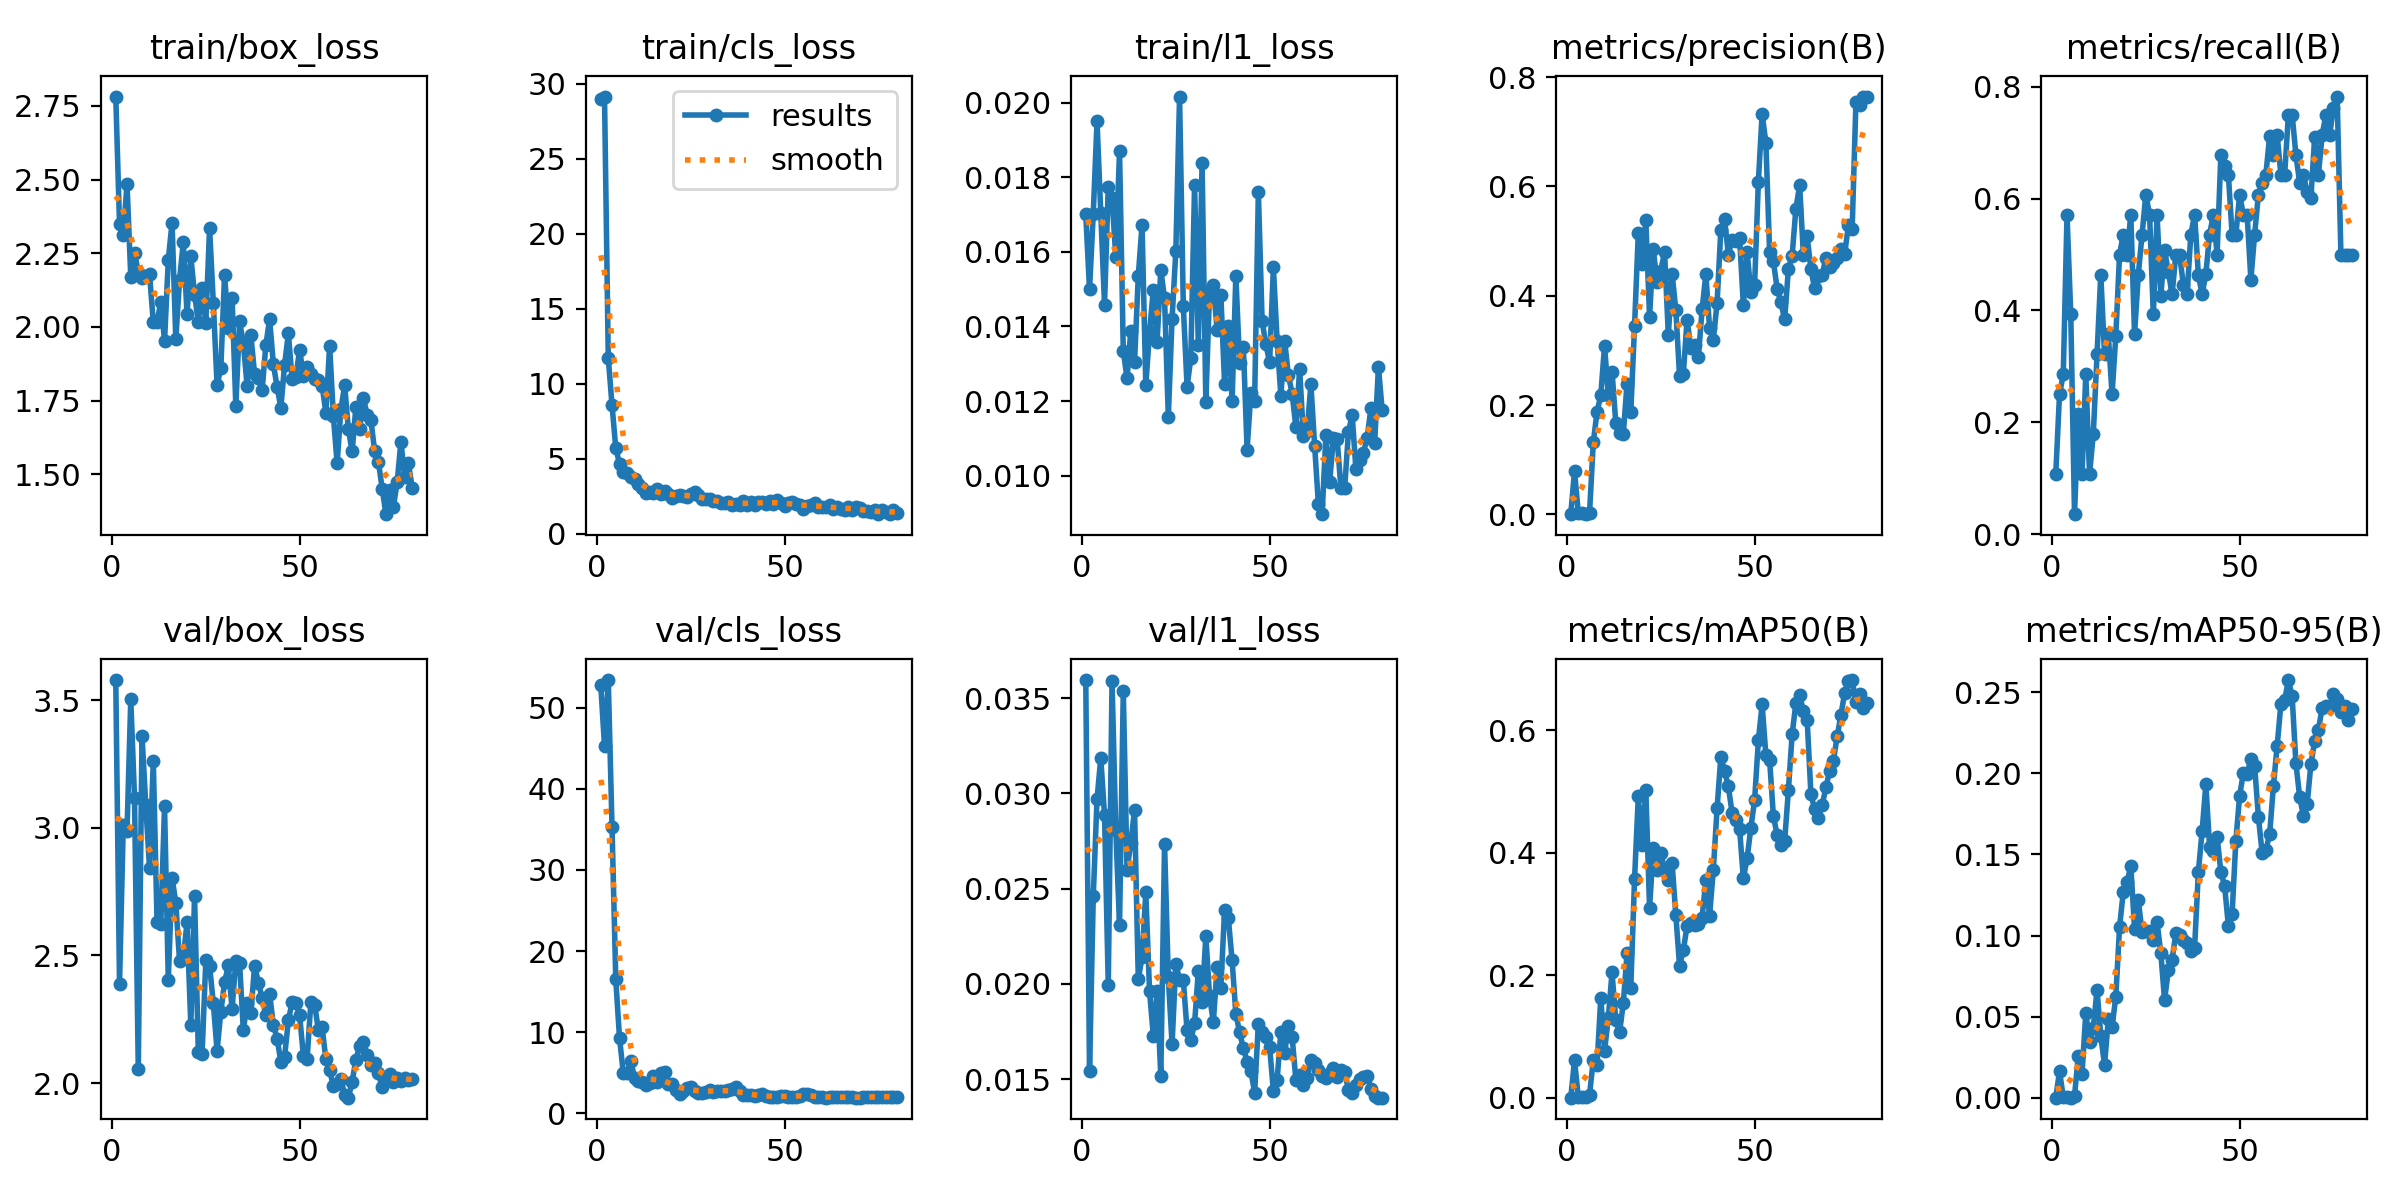

In [10]:
BEST_CONFIG = max(val_results, key=lambda k: val_results[k]['AP50'])
BEST = Path(val_results[BEST_CONFIG]['weights'])
print('Selected:', BEST_CONFIG)
display(Image.open(BEST.parent.parent/'results.png'))

In [11]:
import torch
import numpy as np
from PIL import Image, ImageDraw
from torchvision.transforms.functional import pil_to_tensor
from torchmetrics.detection.mean_ap import MeanAveragePrecision


def target_for_record(record, names, task, label_offset=0):
    objects = record['objects']
    target = {'boxes':torch.tensor([o['box'] for o in objects],dtype=torch.float32).reshape(-1,4),
              'labels':torch.tensor([names.index(o['label'])+label_offset for o in objects],dtype=torch.int64)}
    if task == 'segment':
        masks=[]
        for o in objects:
            if o['polygon'] is None: raise ValueError('Masks need polygon labels.')
            mask=Image.new('L',(record['width'],record['height']),0)
            ImageDraw.Draw(mask).polygon([tuple(p) for p in o['polygon']],fill=1)
            masks.append(torch.from_numpy(np.array(mask,dtype=bool)))
        target['masks']=torch.stack(masks) if masks else torch.zeros((0,record['height'],record['width']),dtype=torch.bool)
    return target


def predict_yolo(model, record, device, task, image_size=640):
    result=model.predict(record['image'],device=device,imgsz=image_size,conf=0.001,
                         max_det=100,retina_masks=True,verbose=False)[0]
    pred={'boxes':result.boxes.xyxy.cpu(), 'labels':result.boxes.cls.cpu().long(), 'scores':result.boxes.conf.cpu()}
    if task == 'segment':
        pred['masks']=(result.masks.data.cpu()>=0.5) if result.masks is not None else torch.zeros((0,record['height'],record['width']),dtype=torch.bool)
    return pred


def evaluate_predictions(rows, names, task, predict_one):
    # Both lessons use this same COCO-style evaluator on ORIGINAL image coordinates.
    # Retain low-score detections for AP; the display threshold is separate.
    metrics={'box':MeanAveragePrecision(iou_type='bbox',class_metrics=True)}
    if task == 'segment': metrics['mask']=MeanAveragePrecision(iou_type='segm',class_metrics=True)
    for r in rows:
        prediction=predict_one(r); truth=target_for_record(r,names,task)
        for metric in metrics.values(): metric.update([prediction],[truth])
    report={}
    for prefix,metric in metrics.items():
        result=metric.compute()
        for key in ['map','map_50','map_75','mar_100']:
            report[prefix+'_'+key]=float(result[key])
        report[prefix+'_per_class_AP']={names[int(c)]:float(v) for c,v in zip(result['classes'].reshape(-1),result['map_per_class'].reshape(-1))}
    return report


def draw_prediction(record, prediction, names, threshold=0.5):
    im=Image.open(record['image']).convert('RGB')
    keep=prediction['scores']>=threshold
    if 'masks' in prediction:
        pixels=np.array(im).copy()
        for mask in prediction['masks'][keep].numpy(): pixels[mask]=(0.65*pixels[mask]+0.35*np.array([0,255,255])).astype(np.uint8)
        im=Image.fromarray(pixels)
    draw=ImageDraw.Draw(im)
    for box,label,score in zip(prediction['boxes'][keep],prediction['labels'][keep],prediction['scores'][keep]):
        draw.rectangle(box.tolist(),outline='red',width=3)
        draw.text(tuple(box[:2].tolist()),f'{names[int(label)]}: {float(score):.2f}',fill='red')
    return im, int(keep.sum())

In [12]:
best_model = YOLO(str(BEST))
predict_one = lambda r: predict_yolo(best_model, r, GPU, TASK, IMAGE_SIZE)
validation_metrics = evaluate_predictions(splits['val'], CLASS_NAMES, TASK, predict_one)
print(json.dumps(validation_metrics, indent=2))
(RUN/'validation_metrics.json').write_text(json.dumps(validation_metrics, indent=2))

{
  "box_map": 0.27382391691207886,
  "box_map_50": 0.657845139503479,
  "box_map_75": 0.13143938779830933,
  "box_mar_100": 0.5428571701049805,
  "box_per_class_AP": {
    "pole": 0.27382391691207886
  }
}


206

## 9. Final test (run once, after choosing the settings)
- **Precision and recall** come from Ultralytics `val()` at **IoU = 0.50**. Ultralytics reports them at the confidence where F1 is highest.
- **AP50** uses IoU = 0.50. **AP50-95** averages IoU 0.50 to 0.95.

In [13]:
test = best_model.val(data=str(DATA_YAML), split='test', imgsz=IMAGE_SIZE, device=GPU,
                      project=str(RUN), name='test')
test_metrics = {'precision@IoU0.5': test.box.mp, 'recall@IoU0.5': test.box.mr,
                'AP50': test.box.map50, 'AP50_95': test.box.map}
test_metrics['torchmetrics'] = evaluate_predictions(splits['test'], CLASS_NAMES, TASK, predict_one)
print(json.dumps(test_metrics, indent=2))
(RUN/'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))

Ultralytics 8.4.170 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 118.8±87.8 MB/s, size: 650.7 KB)
val: Scanning /content/pole-detection/yolo-pole-20261024-200854/yolo-data/labels/test... 28 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 188.8it/s 0.1s
val: New cache created: /content/pole-detection/yolo-pole-20261024-200854/yolo-data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.0s/it 2.1s
                   all         28         30      0.581      0.533      0.492      0.181
Speed: 15.1ms preprocess, 25.3ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to /content/pole-detection/yolo-pole-20261024-200854/test
{
  "precision@IoU0.5": 0.5814307266277022,
  "recall@IoU0.5": 0.5333333333333333,
  "AP50": 0.4924986780328776

390

## 10. Look at successes and failures
Left: annotation (green). Right: predictions with confidence ≥ `DISPLAY_THRESHOLD` (red). Each test image is labeled **success** (same number of poles), **missed** (fewer predicted than annotated), or **false detection** (more predicted than annotated). This is only a quick count check; the images show the real situation.

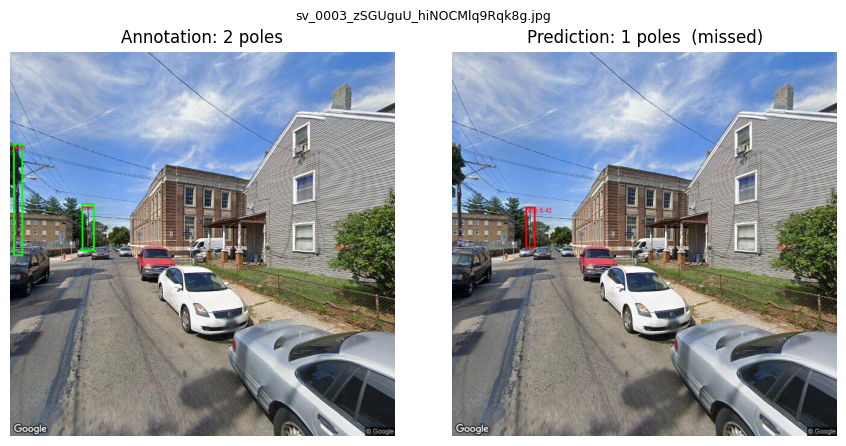

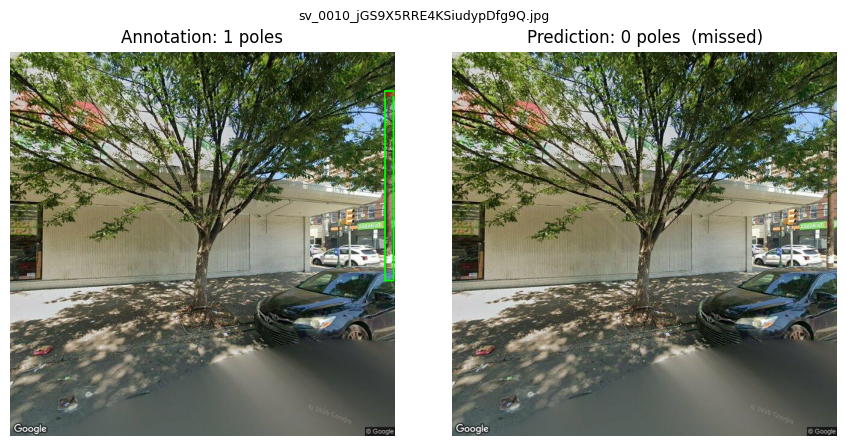

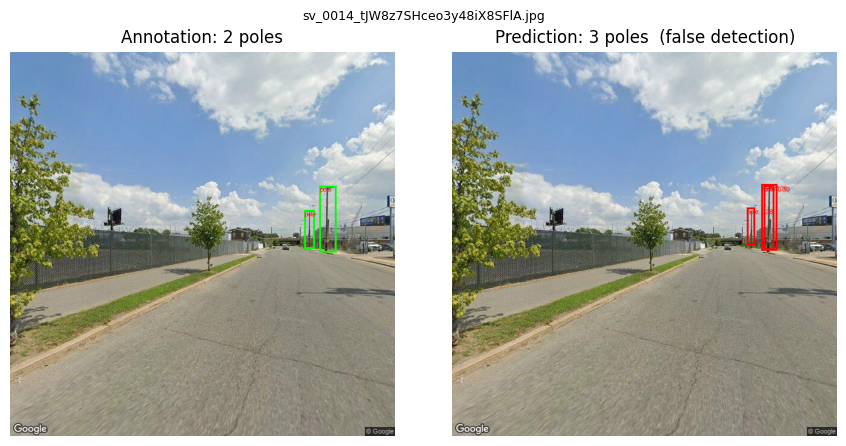

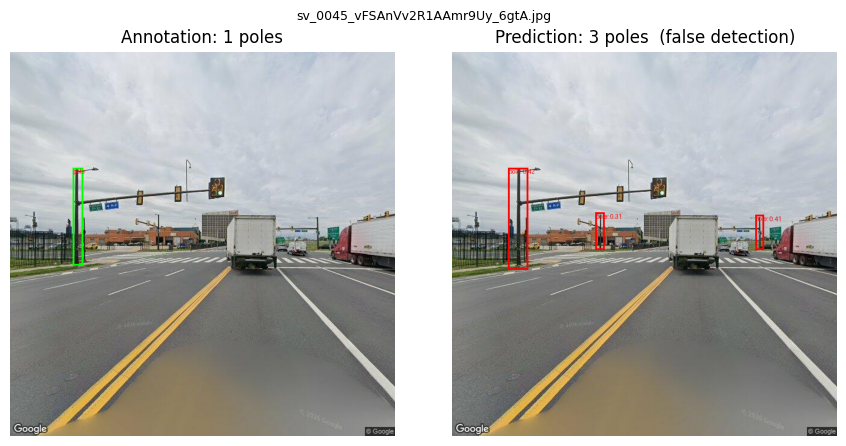

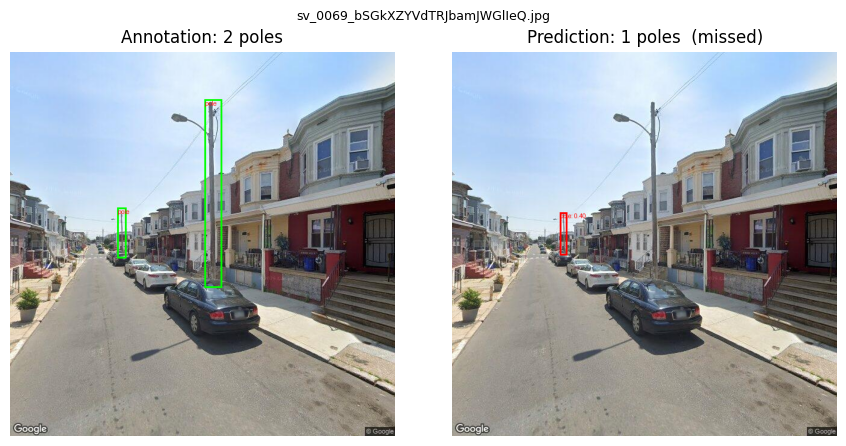

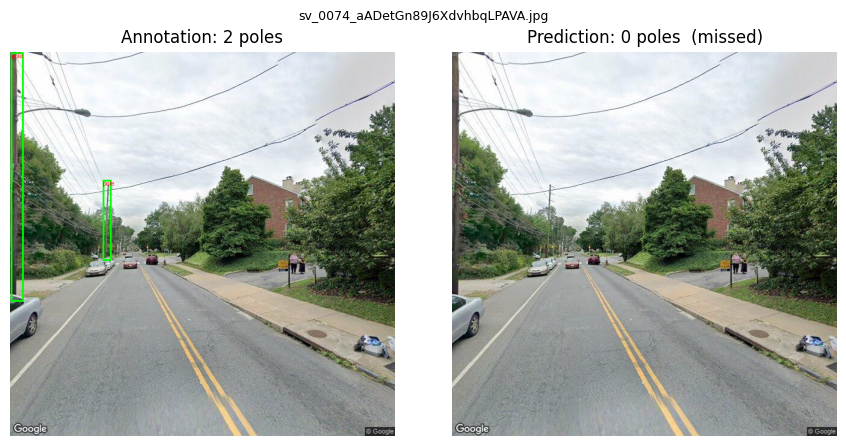

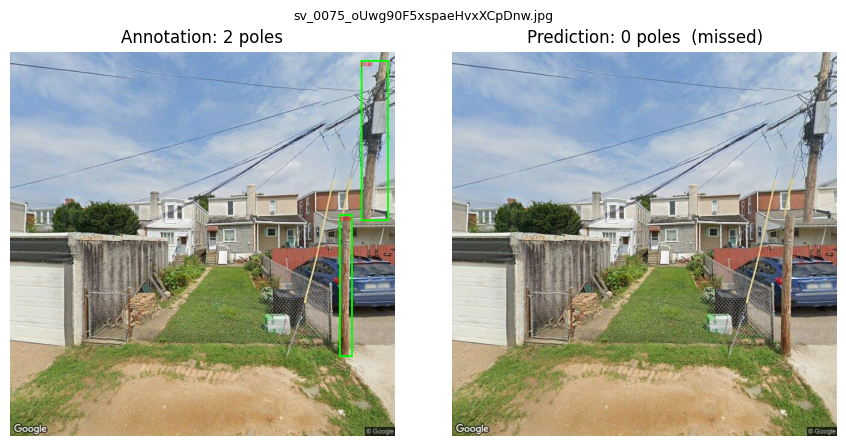

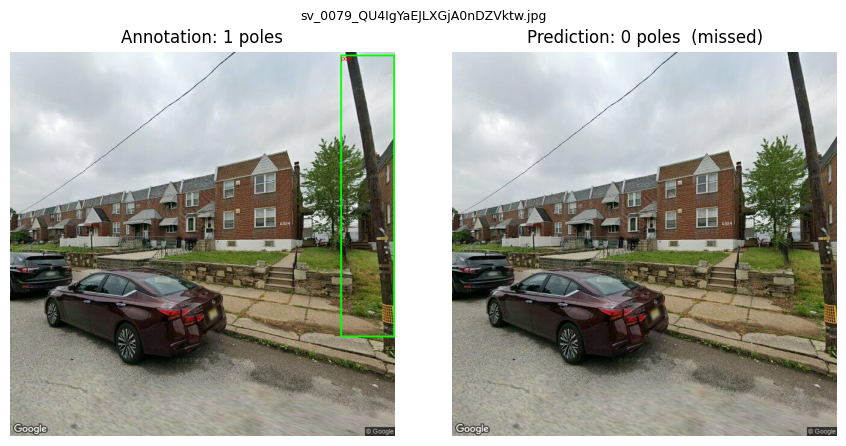

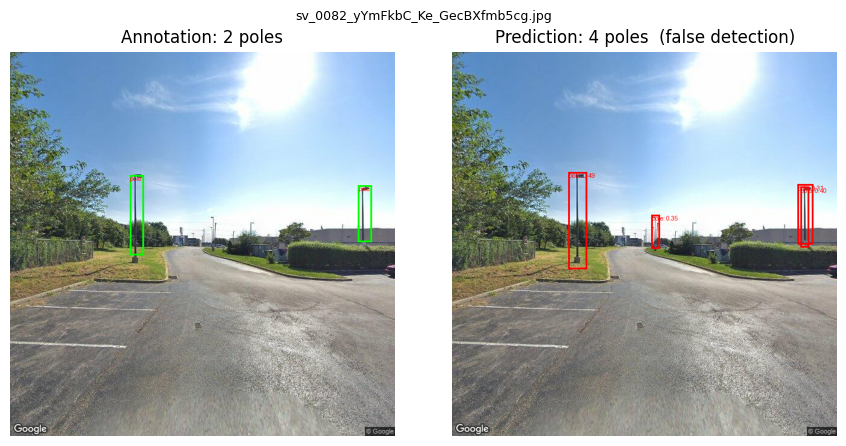

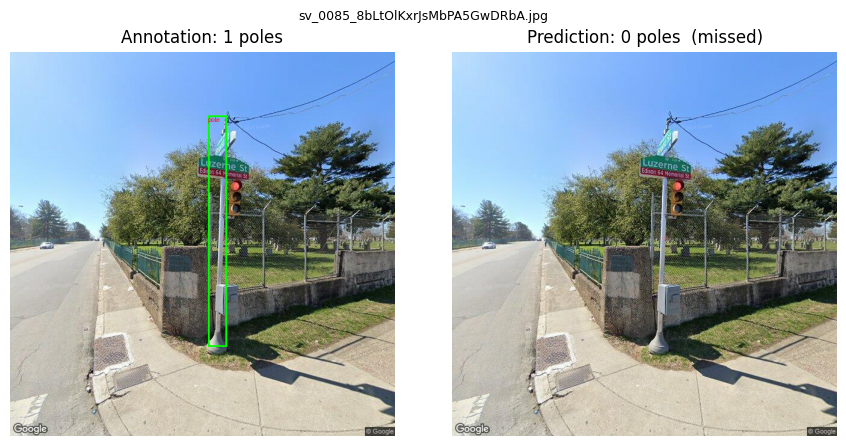

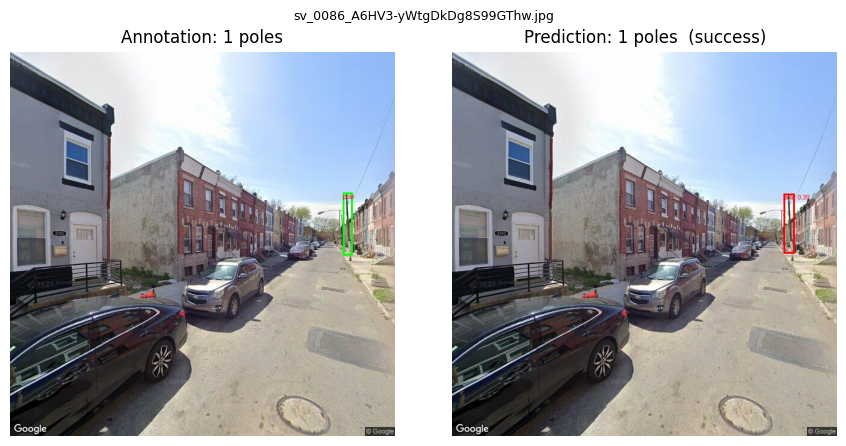

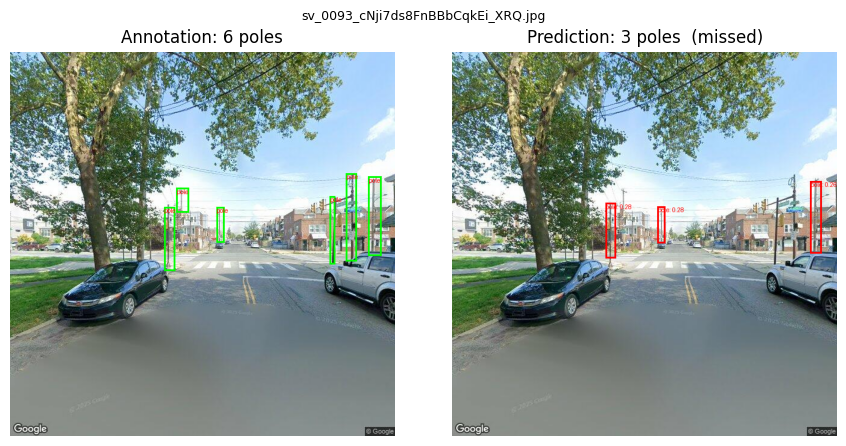

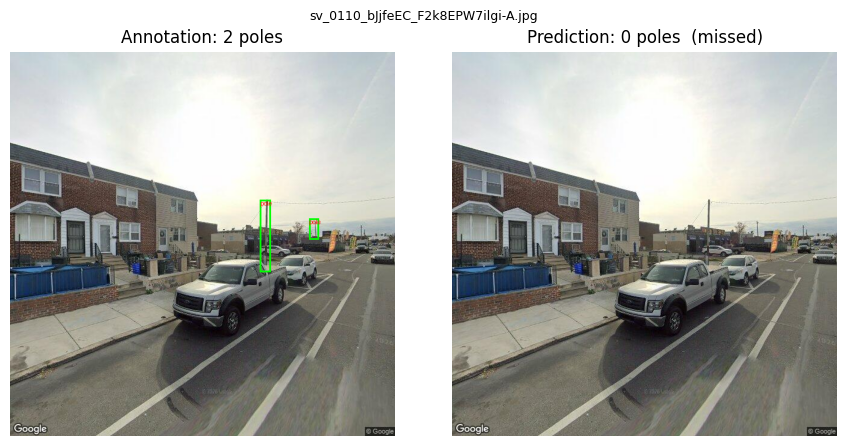

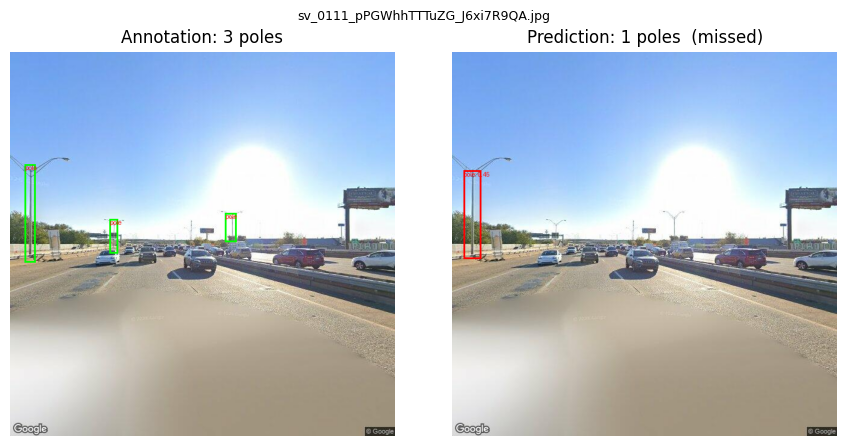

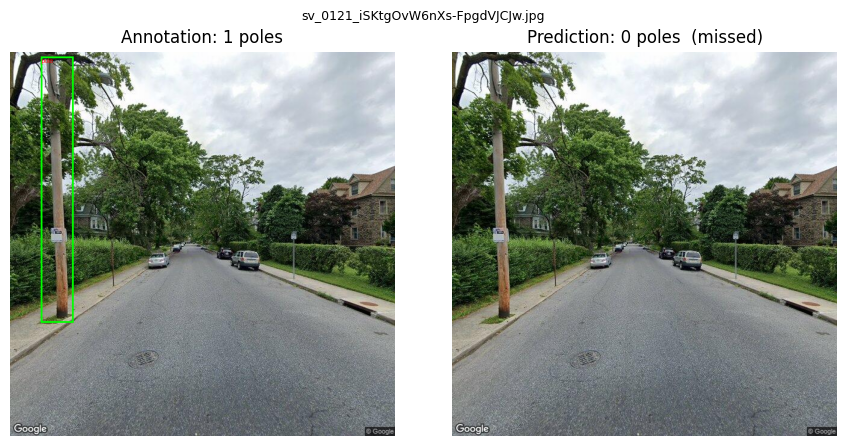

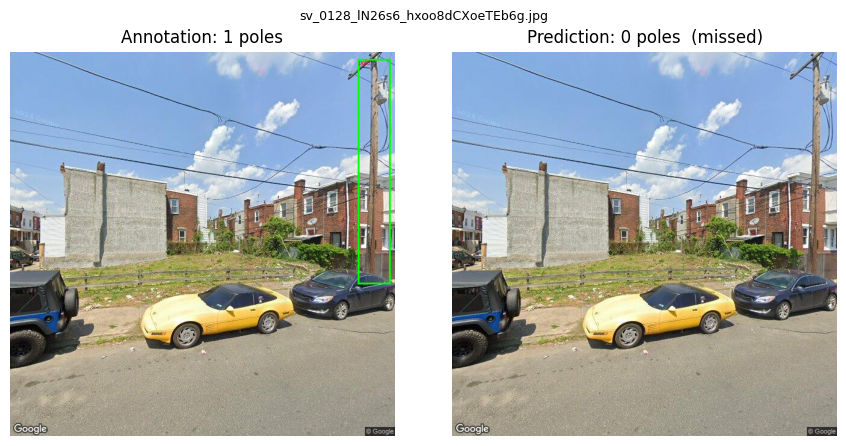

In [14]:
DISPLAY_THRESHOLD = 0.25
for record in splits['test']:
    prediction = predict_one(record)
    predicted_image, count = draw_prediction(record, prediction, CLASS_NAMES, DISPLAY_THRESHOLD)
    n_true = len(record['objects'])
    if n_true == 0 and count == 0:
        continue  # skip correct background images
    kind = 'success' if count == n_true else 'missed' if count < n_true else 'false detection'
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    axes[0].imshow(draw_ground_truth(record)); axes[0].set_title(f'Annotation: {n_true} poles')
    axes[1].imshow(predicted_image); axes[1].set_title(f'Prediction: {count} poles  ({kind})')
    for ax in axes: ax.axis('off')
    fig.suptitle(Path(record['image']).name, fontsize=9)
    plt.tight_layout(); plt.savefig(RUN/f"test_{Path(record['image']).stem}.jpg"); plt.show()

## 12. Report

### Target category
**`pole`**: utility poles (wood or metal) and streetlight poles standing along the street. Poles carry power lines, telecom cables and street lights. Mapping them helps with planning to bury power lines, checking street-light coverage, and finding sidewalk obstacles. `pole` is not one of the 80 COCO classes in the pretrained YOLO26 checkpoint.

**Labeling rule:** one box per visible pole, from the bottom (or the image edge) to the top of the shaft. Poles cut off by the image border are labeled too.

### Images and sources
- **148 Google Street View images** (640×640, field of view 90°, pitch 0°), downloaded with the Street View Static API by `random_streetview.py`.
- Locations are random points inside the Philadelphia city boundary (from OpenStreetMap), with a random camera direction. Capture dates go from 2007 to 2026 (most from 2019–2026), so lighting, season and background vary.
- **90 images contain poles** (142 boxes, labeled in LabelMe). **58 images contain no pole** and are used as background images.
- Pole size varies a lot: box height 35–542 px (median 149 px), width 5–96 px (median 23 px).
- **Usage:** the images are © Google and are used for non-commercial coursework under the Google Maps Platform Terms of Service. They are not shared publicly; only labels and results are submitted.

### Dataset split
Split by location: panoramas closer than 150 m are in the same split. Seed 42.

| Split | Images | Background images | Poles |
|---|---|---|---|
| Train | 89 | 34 | 84 |
| Validation | 31 | 12 | 28 |
| Test | 28 | 12 | 30 |

The exact split is in `split_assignment.json`.

### Training settings
Fine-tuned from COCO-pretrained YOLO26 (Ultralytics 8.4.170) on a Tesla T4. Up to 80 epochs with early stopping (patience 25), image size 640, batch 8, seed 42. Three settings were compared on the **validation** set (Ultralytics val, IoU 0.5 for precision / recall / AP50):

| Setting | Precision | Recall | AP50 | AP50-95 | Best epoch | Training time |
|---|---|---|---|---|---|---|
| A: yolo26n, flips only | 0.596 | 0.607 | 0.579 | 0.234 | 16 (stopped at 41) | 2.0 min |
| B: yolo26n, + augmentation | 0.654 | 0.607 | 0.603 | 0.217 | 19 (stopped at 44) | 2.1 min |
| **C: yolo26s, + augmentation** | 0.487 | 0.750 | **0.646** | **0.261** | ran all 80 | 4.4 min |

**Selected: C (yolo26s with augmentation).** It has the highest validation AP50 and AP50-95. The two nano models stopped improving early. The small model kept improving for all 80 epochs. With the course TorchMetrics evaluator, model C gets validation AP50 = 0.658 and AP50-95 = 0.274.

### Test results (untouched test set: 28 images, 30 poles)

| Metric | IoU threshold | Value |
|---|---|---|
| Precision | 0.50 | **0.581** |
| Recall | 0.50 | **0.533** |
| AP50 | 0.50 | **0.492** |
| AP50-95 | 0.50–0.95 | **0.181** |
| AP50 (TorchMetrics, course evaluator) | 0.50 | 0.513 |
| AP50-95 (TorchMetrics, course evaluator) | 0.50–0.95 | 0.204 |

Precision and recall are from Ultralytics at the confidence with the best F1. The test AP50 (0.49) is lower than validation (0.65). With only 30 test poles, a few poles change the numbers a lot. AP50-95 is much lower than AP50 because poles are very thin. A box that is a few pixels off sideways, or has a slightly wrong top or bottom, quickly falls below a high IoU.

### Successes, missed poles and false detections
(Predictions shown at confidence ≥ 0.25 in Section 10.)

- **Successes:**
  - Medium-size poles on the sidewalk, seen against the sky or a plain building wall, are found well, for example `sv_0086` and the two right-side poles in `sv_0014`.
  - **All 12 background test images had no false detections**, so the model does not fire on ordinary streets without poles.
- **Missed poles:**
  - *Large poles very close to the camera, often cut off by the image edge.* This is the most common miss: `sv_0010`, `sv_0074`, `sv_0075`, `sv_0079`, `sv_0121`, `sv_0128`, and the near pole in `sv_0003`. Only part of the pole is visible and it is much wider than a typical training pole. In `sv_0069` and `sv_0003` the model finds the smaller distant pole but misses the big near one.
  - *Strong backlight and sun glare* (`sv_0110`, `sv_0111`). The poles become dark, low-contrast lines against a very bright sky.
  - *Poles with a lot of equipment, or other pole types.* Transformers and wires hide the shaft in `sv_0075`. The street-sign/traffic-light pole in `sv_0085` looks different from a utility pole.
  - *Crowded scenes with many small poles* (`sv_0093`: 6 annotated, 3 predicted, all with low confidence).
- **False detections:**
  - *Look-alike vertical objects at large intersections:* traffic-signal poles and sign posts (`sv_0045`). Our labeling rule is not fully clear for traffic-signal poles, so the model is unsure about them.
  - *Duplicate boxes on one pole*, where a full box and a second box overlap (`sv_0014`, right pole in `sv_0082`).
  - *Possibly unlabeled poles:* the small box in the middle of `sv_0082` may be a real distant pole that was not labeled, so part of the error is label noise.

### Limitations
- **Small dataset** (89 training images, 84 poles) from **one source** (Google Street View) and **one city**. Results may not hold for other cameras, other cities, night or snow.
- **Small test set** (30 poles), so the test metrics are uncertain.
- **Close-up and cut-off poles are under-represented** in training, which causes most of the missed detections.
- The category boundary is not perfect: traffic-signal poles and sign posts look like utility poles, and distant poles are hard to label consistently.
- Thin objects make box IoU strict, which lowers AP50-95.
- Counting poles in a few images is not the same as counting all poles in the city.
- **Possible improvements:**
  - More images, including other sources such as Mapillary, and more close-up / cut-off poles.
  - A clearer rule for traffic-signal poles.
  - A larger input size (e.g. 960) for thin, distant poles.